# 实验报告02：NumPy、SciPy、Matplotlib 与 pandas 数据处理

| 项目 | 内容 |
| --- | --- |
| 学号 | **20244080209** |
| 姓名 | **何启恒** |
| 实验名称 | 实验02：NumPy、SciPy、Matplotlib 与 pandas 数据处理 |
| 开发环境 | conda 虚拟环境 `exp02`（Python 3.12）+ Jupyter Notebook |

> 本次实验按要求使用**独立的 conda 虚拟环境**（不使用 base 环境），
> 环境准备好后从上到下依次运行所有单元格即可。


## 实验环境说明（conda 虚拟环境）

本实验不使用 base 环境，使用独立虚拟环境 `exp02`：

```bash
# 1. 创建独立虚拟环境（Python 3.12）
conda create -n exp02 python=3.12 -y

# 2. 激活环境
conda activate exp02

# 3. 安装本次实验需要的包
pip install numpy scipy matplotlib pandas jupyter nbconvert

# 4. 启动 Jupyter Notebook
jupyter notebook
```

在 VS Code / PyCharm 中打开本 Notebook 后，把内核切换为 `exp02`，
然后 **Restart Kernel → Run All**，即可得到下方全部运行结果。
涉及随机抽样的步骤均已设置固定随机种子。


## 一、身份与环境记录

In [1]:
import os
import uuid
import hashlib
import platform

import numpy as np
import scipy
import matplotlib
import pandas as pd

# ===== 填写学号 =====
STUDENT_ID = 20244080209

# ===== 记录当前 conda 环境 =====
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")

# ===== 机器指纹（绑定当前电脑） =====
MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]

# ===== 生成唯一 RUN_ID =====
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号]       {STUDENT_ID}")
print(f"[机器指纹]   {MACHINE_FP}")
print(f"[RUN_ID]     {RUN_ID}")

# ===== 依赖版本记录 =====
print(f"[NumPy]      {np.__version__}")
print(f"[SciPy]      {scipy.__version__}")
print(f"[Matplotlib] {matplotlib.__version__}")
print(f"[pandas]     {pd.__version__}")


[Conda 环境] exp02
[学号]       20244080209
[机器指纹]   8c49fe190c554f6a
[RUN_ID]     20244080209-8c49fe190c554f6a
[NumPy]      2.5.4
[SciPy]      1.18.1
[Matplotlib] 3.11.2
[pandas]     3.0.6


## 二、实验内容与过程

### 实验1：NumPy 数组、数据类型与索引


In [2]:
# bonjour

# 实验1-1：分别创建整数、浮点数、布尔值 ndarray
int_arr = np.array([1, 2, 3, 4], dtype=int)
float_arr = np.array([1.5, 2.5, 3.5, 4.5], dtype=float)
bool_arr = np.array([True, False, True, False], dtype=bool)

for name, arr in [("整数数组", int_arr), ("浮点数组", float_arr), ("布尔数组", bool_arr)]:
    print(f"{name}: {arr}")
    print(f"  dtype = {arr.dtype} | shape = {arr.shape} | ndim = {arr.ndim}")
    print()


整数数组: [1 2 3 4]
  dtype = int64 | shape = (4,) | ndim = 1

浮点数组: [1.5 2.5 3.5 4.5]
  dtype = float64 | shape = (4,) | ndim = 1

布尔数组: [ True False  True False]
  dtype = bool | shape = (4,) | ndim = 1



**NumPy 数组与 Python 列表的差别**

- **数据类型**：Python 列表可以混合存放不同类型的元素；ndarray 是**同质**的，所有元素共用同一个 `dtype`（如 int64、float64、bool）。
- **内存与运算**：ndarray 在内存中连续存储，支持向量化（逐元素）运算，速度快、代码简洁；列表的逐元素运算通常需要循环。
- **形状信息**：ndarray 自带 `shape`、`ndim`、`size` 等形状属性；普通列表没有统一的形状概念，嵌套列表的层级也不固定。
- **切片与视图**：ndarray 切片默认是原数组的**视图**，修改视图会影响原数组；列表切片是新列表（浅拷贝）。


In [3]:
# 实验1-2：np.arange(12) 变形为 (3, 4) 与 (2, 3, 2)
a1d = np.arange(12)
print("一维数组 arange(12):", a1d)
print("shape:", a1d.shape, "| ndim:", a1d.ndim)

a34 = a1d.reshape(3, 4)
print("\n形状 (3, 4):")
print(a34)
print("shape:", a34.shape, "| ndim:", a34.ndim)

a232 = a1d.reshape(2, 3, 2)
print("\n形状 (2, 3, 2):")
print(a232)
print("shape:", a232.shape, "| ndim:", a232.ndim)

print("\n元素总数: 一维 =", a1d.size, ", (3,4) =", a34.size, ", (2,3,2) =", a232.size)


一维数组 arange(12): [ 0  1  2  3  4  5  6  7  8  9 10 11]
shape: (12,) | ndim: 1

形状 (3, 4):
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
shape: (3, 4) | ndim: 2

形状 (2, 3, 2):
[[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]
shape: (2, 3, 2) | ndim: 3

元素总数: 一维 = 12 , (3,4) = 12 , (2,3,2) = 12


**改变形状的条件**：`reshape` 只改变数组的维度排列，不改变元素个数；新形状各维长度的乘积必须**等于**原数组的元素总数（`size` 不变）。例如 12 个元素可以排成 (3, 4) 或 (2, 3, 2)，但不能排成 (3, 3)（共需 9 个元素）。元素按行优先（C 顺序）重新填充到新形状中。


In [4]:
# 实验1-3：对 (3, 4) 数组完成索引
arr = np.arange(1, 13).reshape(3, 4)
print("原始数组 (3, 4):")
print(arr)

# 取第 2 行（下标 1）
row2 = arr[1, :]
print("\n第 2 行:", row2, "| shape:", row2.shape)

# 取第 1 至第 3 列（下标 0, 1, 2）
cols13 = arr[:, 0:3]
print("\n第 1 至第 3 列:")
print(cols13, "| shape:", cols13.shape)

# 取大于 6 的元素
gt6 = arr[arr > 6]
print("\n大于 6 的元素:", gt6, "| shape:", gt6.shape)


原始数组 (3, 4):
[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]

第 2 行: [5 6 7 8] | shape: (4,)

第 1 至第 3 列:
[[ 1  2  3]
 [ 5  6  7]
 [ 9 10 11]] | shape: (3, 3)

大于 6 的元素: [ 7  8  9 10 11 12] | shape: (6,)


In [5]:
# 实验1-4：布尔条件筛选
x = np.arange(10)
print("原始数组:", x)

# 小于 2 或大于 7
mask_or = (x < 2) | (x > 7)
print("小于 2 或大于 7:", x[mask_or])

# 大于 3 且小于 7
mask_and = (x > 3) & (x < 7)
print("大于 3 且小于 7:", x[mask_and])

# 等价写法：np.logical_or / np.logical_and
print("logical_or 等价:", x[np.logical_or(x < 2, x > 7)])
print("logical_and 等价:", x[np.logical_and(x > 3, x < 7)])


原始数组: [0 1 2 3 4 5 6 7 8 9]
小于 2 或大于 7: [0 1 8 9]
大于 3 且小于 7: [4 5 6]
logical_or 等价: [0 1 8 9]
logical_and 等价: [4 5 6]


In [6]:
# 实验1-5：逐元素乘法与矩阵乘法对比
A = np.array([[1, 2], [3, 4]])
B = np.array([[5, 6], [7, 8]])

print("A =\n", A)
print("B =\n", B)

print("\nA * B（逐元素乘）=\n", A * B)
print("np.multiply(A, B) =\n", np.multiply(A, B))

print("\nA @ B（矩阵乘）=\n", A @ B)
print("np.matmul(A, B) =\n", np.matmul(A, B))


A =
 [[1 2]
 [3 4]]
B =
 [[5 6]
 [7 8]]

A * B（逐元素乘）=
 [[ 5 12]
 [21 32]]
np.multiply(A, B) =
 [[ 5 12]
 [21 32]]

A @ B（矩阵乘）=
 [[19 22]
 [43 50]]
np.matmul(A, B) =
 [[19 22]
 [43 50]]


**逐元素乘法与矩阵乘法的区别**

- `*` / `np.multiply()`：**逐元素（Hadamard）乘法**，要求两个数组形状相同，结果对应位置相乘。
- `@` / `np.matmul()`：**矩阵乘法**，结果第 (i, j) 个元素是第一个矩阵第 i 行与第二个矩阵第 j 列的内积；要求前一矩阵的列数等于后一矩阵的行数。


### 实验2：随机抽样、统计与缺失值

In [7]:
# 实验2-1：生成 1000 个均值 70、标准差 10 的模拟成绩并截断到 0~100
rng = np.random.default_rng(20244080209)

raw_scores = rng.normal(loc=70, scale=10, size=1000)
scores = np.clip(raw_scores, 0, 100)

n = scores.size
print(f"样本数 n      : {n}")
print(f"最小值 min    : {scores.min():.2f}")
print(f"最大值 max    : {scores.max():.2f}")
print(f"均值 mean     : {scores.mean():.2f}")
print(f"标准差 std    : {scores.std():.2f}")
print(f"极差 max-min  : {scores.max() - scores.min():.2f}")


样本数 n      : 1000
最小值 min    : 38.55
最大值 max    : 100.00
均值 mean     : 70.30
标准差 std    : 9.88
极差 max-min  : 61.45


In [8]:
# 实验2-2：不放回抽取 5 个整数，均匀抽样 vs 按大小成比例加权抽样
population = np.arange(1, 11)
print("总体:", population)

# 均匀抽样：每个整数被抽中概率相同
uniform_pick = rng.choice(population, size=5, replace=False)
print("均匀抽样结果        :", np.sort(uniform_pick))

# 按整数大小成比例加权：权重 = 数值 / 数值之和
weights = population / population.sum()
weighted_pick = rng.choice(population, size=5, replace=False, p=weights)
print("按大小比例加权抽样  :", np.sort(weighted_pick))
print("加权概率 p          :", np.round(weights, 3))


总体: [ 1  2  3  4  5  6  7  8  9 10]
均匀抽样结果        : [2 4 5 6 8]
按大小比例加权抽样  : [ 5  6  8  9 10]
加权概率 p          : [0.018 0.036 0.055 0.073 0.091 0.109 0.127 0.145 0.164 0.182]


In [9]:
# 实验2-3：随机排列（保留原数组）vs 原地打乱
original = np.arange(1, 11)

# 方式一：rng.permutation 返回新数组，原数组不变
arr_copy = original.copy()
permuted = rng.permutation(arr_copy)
print("permutation 后原数组:", original, "（未被改动）")
print("返回的新排列        :", permuted)

# 方式二：rng.shuffle 原地打乱，原数组直接改变
arr_inplace = original.copy()
print("\nshuffle 前:", arr_inplace)
rng.shuffle(arr_inplace)
print("shuffle 后:", arr_inplace, "（原数组被就地打乱）")
print("原始 original 仍为 :", original)


permutation 后原数组: [ 1  2  3  4  5  6  7  8  9 10] （未被改动）
返回的新排列        : [ 9  4  7  2  8  5  3  6  1 10]

shuffle 前: [ 1  2  3  4  5  6  7  8  9 10]
shuffle 后: [ 3  8  2 10  1  5  9  6  4  7] （原数组被就地打乱）
原始 original 仍为 : [ 1  2  3  4  5  6  7  8  9 10]


In [10]:
# 实验2-4：制造缺失值并比较均值
scores_nan = scores.copy()
# 第 10、20、30 个值（下标 9、19、29）设为 np.nan
scores_nan[[9, 19, 29]] = np.nan

missing_count = int(np.isnan(scores_nan).sum())
normal_mean = scores_nan.mean()          # 含 nan 的普通均值
nanmean = np.nanmean(scores_nan)         # 忽略缺失值后的均值

print(f"缺失值个数       : {missing_count}")
print(f"普通均值 mean()  : {normal_mean}")
print(f"忽略缺失值均值   : {nanmean:.2f}")
print(f"有效样本数       : {np.isfinite(scores_nan).sum()}")


缺失值个数       : 3
普通均值 mean()  : nan
忽略缺失值均值   : 70.25
有效样本数       : 997


**np.nan 对统计函数的影响**：`np.nan` 是浮点特殊值，任何与它参与的算术运算结果都是 `nan`。普通的 `mean()`、`sum()`、`std()` 一旦遇到 `nan`，整个统计结果就会被污染成 `nan`；需要使用 `np.nanmean()`、`np.nanstd()` 等忽略缺失值的函数，或先用 `np.isfinite()` 过滤掉缺失值再统计。


In [11]:
# 实验2-5：把含缺失值的成绩与序号整理成内存表格（不写磁盘）
score_table = pd.DataFrame({
    "序号": np.arange(1, scores_nan.size + 1),
    "成绩": scores_nan,
})
print("内存表格前 5 行:")
print(score_table.head())
print("表格形状:", score_table.shape)

# 同时演示内存中的 CSV 读写：经 io.StringIO 往返，不落盘
import io
buf = io.StringIO()
score_table.to_csv(buf, index=False, encoding="utf-8")
buf.seek(0)
score_table_csv = pd.read_csv(buf)
# NaN 在 equals 中按不等处理，需分别比较缺失位置与非缺失数值
same_missing = bool((np.isnan(score_table["成绩"].to_numpy())
                     == np.isnan(score_table_csv["成绩"].to_numpy())).all())
same_values = bool(np.allclose(score_table["成绩"].dropna(),
                               score_table_csv["成绩"].dropna()))
print("\n经内存 CSV 往返后形状:", score_table_csv.shape)
print("往返后缺失值位置一致:", same_missing)
print("往返后非缺失数值一致:", same_values)


内存表格前 5 行:
   序号         成绩
0   1  77.245154
1   2  78.931880
2   3  77.311197
3   4  94.810176
4   5  67.333699
表格形状: (1000, 2)

经内存 CSV 往返后形状: (1000, 2)
往返后缺失值位置一致: True
往返后非缺失数值一致: True


### 实验3：SciPy 数值计算与 Matplotlib 可视化

In [12]:
# 实验3-1：解线性方程组 3x + y = 9, x + 2y = 8
from scipy.linalg import solve

# 系数矩阵 A 与右端向量 b
A = np.array([[3, 1], [1, 2]])
b = np.array([9, 8])

sol = solve(A, b)
x, y = sol
print(f"解: x = {x:.4f}, y = {y:.4f}")

# 用 NumPy 代入验证
residual = A @ sol - b
print("代入验证 A·解 - b =", residual, "（接近 0 即正确）")
print("第一式 3x+y =", round(3 * x + y, 6), "| 第二式 x+2y =", round(x + 2 * y, 6))


解: x = 2.0000, y = 3.0000
代入验证 A·解 - b = [1.77635684e-15 0.00000000e+00] （接近 0 即正确）
第一式 3x+y = 9.0 | 第二式 x+2y = 8.0


In [13]:
# 实验3-2：求方程 x² - 2 = 0 的正根与负根
from scipy.optimize import root

def f(x):
    return x ** 2 - 2

# 正根：初始猜测 +1；负根：初始猜测 -1
res_pos = root(f, x0=1.0)
res_neg = root(f, x0=-1.0)

print("正根求解成功:", res_pos.success, "| 结果 x =", round(res_pos.x[0], 6),
      "| 函数值 f(x) =", round(f(res_pos.x[0]), 10))
print("负根求解成功:", res_neg.success, "| 结果 x =", round(res_neg.x[0], 6),
      "| 函数值 f(x) =", round(f(res_neg.x[0]), 10))


正根求解成功: True | 结果 x = 1.414214 | 函数值 f(x) = -0.0
负根求解成功: True | 结果 x = -1.414214 | 函数值 f(x) = -0.0


In [14]:
# 实验3-3：求 f(x) = x² + x + 2 的最小值
from scipy.optimize import minimize

def objective(x):
    return x[0] ** 2 + x[0] + 2

res = minimize(objective, x0=0.0)
x_min = res.x[0]
f_min = res.fun

print(f"极小点 x = {x_min:.6f}")
print(f"极小值 f(x) = {f_min:.6f}")

# 解析结果：f'(x) = 2x + 1 = 0 -> x = -0.5，f(-0.5) = 1.75
print(f"解析解: x = -0.5, f(-0.5) = {(-0.5) ** 2 + (-0.5) + 2}")
print("数值解与解析解是否一致:", np.isclose(x_min, -0.5) and np.isclose(f_min, 1.75))


极小点 x = -0.500000
极小值 f(x) = 1.750000
解析解: x = -0.5, f(-0.5) = 1.75
数值解与解析解是否一致: True


In [15]:
# 实验3-4：两组独立样本 t 检验
rng_ttest = np.random.default_rng(20244080209)
group1 = rng_ttest.normal(loc=0, scale=1, size=100)
group2 = rng_ttest.normal(loc=1, scale=1, size=100)

from scipy import stats
t_stat, p_value = stats.ttest_ind(group1, group2)

print(f"组1 均值 = {group1.mean():.4f} | 组2 均值 = {group2.mean():.4f}")
print(f"t 统计量 = {t_stat:.4f}")
print(f"p 值     = {p_value:.6f}")

alpha = 0.05
if p_value < alpha:
    print(f"在 0.05 显著性水平下：p < {alpha}，拒绝原假设，两组均值存在显著差异。")
else:
    print(f"在 0.05 显著性水平下：p >= {alpha}，不能拒绝原假设。")


组1 均值 = 0.0563 | 组2 均值 = 1.1627
t 统计量 = -7.7781
p 值     = 0.000000
在 0.05 显著性水平下：p < 0.05，拒绝原假设，两组均值存在显著差异。


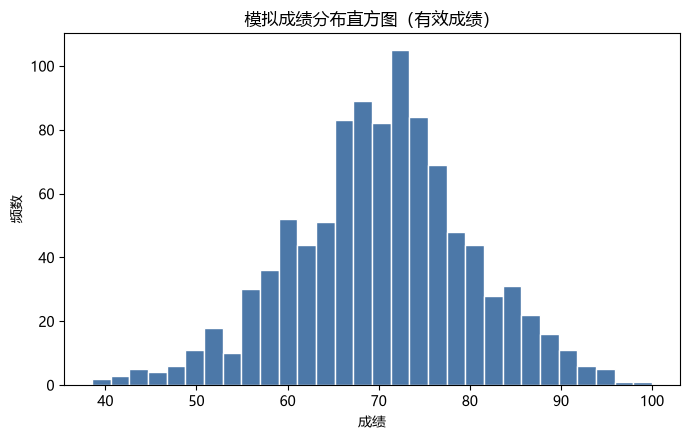

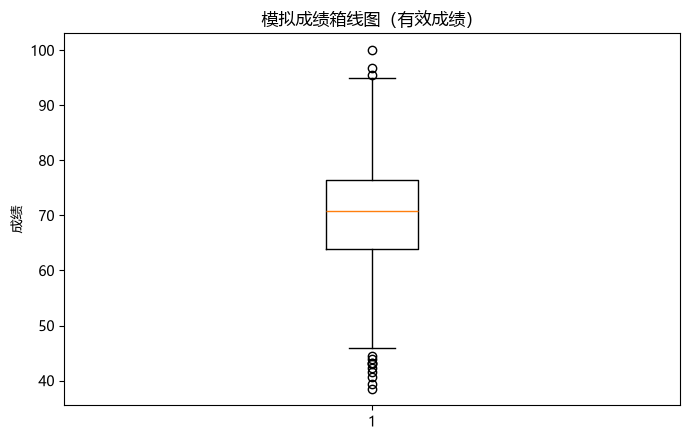

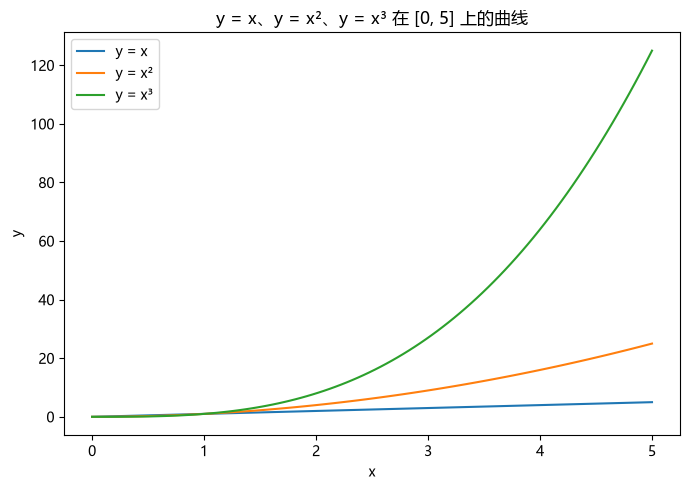

In [16]:
# 实验3-5：可视化（直方图、箱线图、函数折线图）
import matplotlib.pyplot as plt

# 配置中文字体与负号显示
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

valid_scores = scores_nan[np.isfinite(scores_nan)]

# 1) 有效成绩直方图
plt.figure(figsize=(7, 4.5))
plt.hist(valid_scores, bins=30, color="#4C78A8", edgecolor="white")
plt.title("模拟成绩分布直方图（有效成绩）")
plt.xlabel("成绩")
plt.ylabel("频数")
plt.tight_layout()
plt.show()

# 2) 有效成绩箱线图
plt.figure(figsize=(7, 4.5))
plt.boxplot(valid_scores, orientation="vertical")
plt.title("模拟成绩箱线图（有效成绩）")
plt.ylabel("成绩")
plt.tight_layout()
plt.show()

# 3) y = x, y = x², y = x³ 在 [0, 5] 上的折线图
x = np.linspace(0, 5, 100)
plt.figure(figsize=(7, 5))
plt.plot(x, x, label="y = x")
plt.plot(x, x ** 2, label="y = x²")
plt.plot(x, x ** 3, label="y = x³")
plt.title("y = x、y = x²、y = x³ 在 [0, 5] 上的曲线")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.tight_layout()
plt.show()


### 实验4：pandas Series、DataFrame 与内存中的 CSV 读写

In [17]:
# 实验4-1：创建 DataFrame，计算总分与平均分
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}

df = pd.DataFrame(records).set_index("Name")
df["Total"] = df["Math"] + df["English"] + df["Python"]
df["Average"] = df["Total"] / 3

print("行索引:", list(df.index))
print("列名:", list(df.columns))
print("\n前 3 行:")
print(df.head(3))
print("\n基本统计信息:")
print(df.describe())


行索引: ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名: ['Group', 'Math', 'English', 'Python', 'Total', 'Average']

前 3 行:
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333

基本统计信息:
            Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.750000  88.250000  263.000000  87.666667
max    91.000000  92.000000  95.000000  273.000000  91.000000


In [18]:
# 实验4-2：loc / iloc 读取 Carol；筛选平均分 >= 80
print("loc 读取 Carol:")
print(df.loc["Carol"])

print("\niloc 读取 Carol（行下标 2）:")
print(df.iloc[2])

passed = df[df["Average"] >= 80]
print("\n平均分不低于 80 的学生:")
print(passed[["Group", "Math", "English", "Python", "Average"]])


loc 读取 Carol:
Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

iloc 读取 Carol（行下标 2）:
Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

平均分不低于 80 的学生:
      Group  Math  English  Python    Average
Name                                         
Alice     A    88       90      95  91.000000
Carol     B    91       85      89  88.333333
Eva       A    79       92      86  85.666667
Frank     B    84       77      82  81.000000


In [19]:
# 实验4-3：列均值与行均值
subject_cols = ["Math", "English", "Python"]

col_mean = df[subject_cols].mean(axis=0)
print("三科列均值（axis=0）:")
print(col_mean.round(2))

row_mean = df[subject_cols].mean(axis=1)
print("\n每名学生行均值（axis=1）:")
print(row_mean.round(2))


三科列均值（axis=0）:
Math       79.83
English    80.83
Python     83.67
dtype: float64

每名学生行均值（axis=1）:
Name
Alice    91.00
Bob      73.33
Carol    88.33
David    69.33
Eva      85.67
Frank    81.00
dtype: float64


In [20]:
# 实验4-4：apply 求最高分；agg 一次求 min/mean/max；rank 排名
# 每名学生三科最高分（按行 apply）
df["Max"] = df[subject_cols].apply(lambda row: row.max(), axis=1)
print("每名学生三科最高分:")
print(df[subject_cols + ["Max"]])

# 每科最小值、均值、最大值（agg）
subject_agg = df[subject_cols].agg(["min", "mean", "max"])
print("\n每科 min / mean / max:")
print(subject_agg.round(2))

# 按 Average 排名（分数越高名次越靠前）
df["Average_Rank"] = df["Average"].rank(ascending=False, method="min")
print("\n按平均分排名:")
print(df[["Average", "Average_Rank"]].sort_values("Average_Rank"))


每名学生三科最高分:
       Math  English  Python  Max
Name                             
Alice    88       90      95   95
Bob      72       68      80   80
Carol    91       85      89   91
David    65       73      70   73
Eva      79       92      86   92
Frank    84       77      82   84

每科 min / mean / max:
       Math  English  Python
min   65.00    68.00   70.00
mean  79.83    80.83   83.67
max   91.00    92.00   95.00

按平均分排名:
         Average  Average_Rank
Name                          
Alice  91.000000           1.0
Carol  88.333333           2.0
Eva    85.666667           3.0
Frank  81.000000           4.0
Bob    73.333333           5.0
David  69.333333           6.0


In [21]:
# 实验4-5：按 Group 分组统计；transform 增加组内 Python 平均分
group_stat = df.groupby("Group").agg(
    人数=("Math", "size"),
    Math均值=("Math", "mean"),
    English均值=("English", "mean"),
    Python均值=("Python", "mean"),
)
print("各组人数与三科平均分:")
print(group_stat.round(2))

# transform('mean')：为每行补上其所在组的 Python 平均分
df["Group_Python_Mean"] = df.groupby("Group")["Python"].transform("mean")
print("\n每行所在组的 Python 平均分:")
print(df[["Group", "Python", "Group_Python_Mean"]].round(2))


各组人数与三科平均分:
       人数  Math均值  English均值  Python均值
Group                                 
A       3   79.67      83.33     87.00
B       3   80.00      78.33     80.33

每行所在组的 Python 平均分:
      Group  Python  Group_Python_Mean
Name                                  
Alice     A      95              87.00
Bob       A      80              87.00
Carol     B      89              80.33
David     B      70              80.33
Eva       A      86              87.00
Frank     B      82              80.33


In [22]:
# 实验4-6：filter 保留 Python 平均分 >= 80 的组
def group_python_mean(g):
    return g["Python"].mean() >= 80

kept = df.groupby("Group").filter(group_python_mean)
kept_groups = kept["Group"].unique().tolist()

print("保留的组:", kept_groups)
print("\n保留组内学生:")
print(kept[["Group", "Math", "English", "Python", "Average"]])


保留的组: ['A', 'B']

保留组内学生:
      Group  Math  English  Python    Average
Name                                         
Alice     A    88       90      95  91.000000
Bob       A    72       68      80  73.333333
Carol     B    91       85      89  88.333333
David     B    65       73      70  69.333333
Eva       A    79       92      86  85.666667
Frank     B    84       77      82  81.000000


In [23]:
# 实验4-7：协方差矩阵与皮尔森相关系数矩阵
cov_matrix = df[subject_cols].cov()
corr_matrix = df[subject_cols].corr(method="pearson")

print("协方差矩阵:")
print(cov_matrix.round(4))
print("\n皮尔森相关系数矩阵:")
print(corr_matrix.round(4))

# 解读 Math 与 English 这一对
cov_me = cov_matrix.loc["Math", "English"]
corr_me = corr_matrix.loc["Math", "English"]
print(f"\nMath 与 English：协方差 = {cov_me:.4f}，相关系数 = {corr_me:.4f}")


协方差矩阵:
            Math  English   Python
Math     98.1667  62.5667  74.9333
English  62.5667  93.3667  62.5333
Python   74.9333  62.5333  73.0667

皮尔森相关系数矩阵:
           Math  English  Python
Math     1.0000   0.6535  0.8848
English  0.6535   1.0000  0.7571
Python   0.8848   0.7571  1.0000

Math 与 English：协方差 = 62.5667，相关系数 = 0.6535


**协方差与相关系数解读**（以 Math 与 English 为例）：

- **协方差**为正，表示两科成绩**同向变化**（数学高的学生英语往往也高）；为负表示反向变化；接近 0 表示无线性同向趋势。协方差受量纲影响，不能直接比较强弱。
- **皮尔森相关系数**取值在 [-1, 1]：越接近 1 线性正相关越强，越接近 -1 线性负相关越强，接近 0 表示线性相关很弱。


In [24]:
# 实验4-补充：DataFrame 内存 CSV 读写（io.StringIO，不落盘）
buf2 = io.StringIO()
df.to_csv(buf2, encoding="utf-8")
buf2.seek(0)
df_from_csv = pd.read_csv(buf2, index_col=0)

print("往返后形状:", df_from_csv.shape)
print("数值与原表是否一致:", np.allclose(df_from_csv[subject_cols], df[subject_cols]))


往返后形状: (6, 9)
数值与原表是否一致: True


### 实验小结

| 实验 | 主要知识点 |
| --- | --- |
| 实验1 | ndarray 创建与 `dtype`/`shape`/`ndim`、`reshape` 变形、行列与布尔索引、逐元素乘法与矩阵乘法 |
| 实验2 | 正态抽样与 `np.clip`、描述统计、均匀/加权不放回抽样、`permutation` 与 `shuffle`、`np.nan` 缺失值与 `nanmean`、内存表格 |
| 实验3 | `scipy.linalg.solve`、`optimize.root`、`optimize.minimize`、独立样本 t 检验、直方图/箱线图/折线图可视化 |
| 实验4 | DataFrame 构建与索引（`loc`/`iloc`）、`mean`/`apply`/`agg`/`rank`、`groupby` 与 `transform`、`filter`、协方差与相关系数、内存 CSV 读写 |

全部单元格已按顺序运行通过，未出现报错。
